# Stage 9: generalisation

Results of `python -m src.generalise`.

1. **Unseen stations**: the final models on stations they never trained on (6 random hold-outs with a
   full 2023, and stations that are new in 2023), next to the seen stations.
2. **Station-grouped 5-fold** for the best GBM: the same stations with and without them in training.
3. **Kaggle transfer check** (1 h): a reduced model with common features only, applied unchanged to a
   different rooftop dataset from 2024-2025.

In [1]:
import pandas as pd
from IPython.display import Image

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
TABLES = "../results/tables/"
FIGURES = "../results/figures/"

## 1. Seen vs unseen stations (test 2023, daytime)

In [2]:
gen = pd.read_csv(TABLES + "09_generalisation.csv")
columns = ["horizon", "model", "group", "stations", "nmae_pct", "nmae_pct_low", "nmae_pct_high", "skill", "mean_station_skill"]
gen[columns].round(3)

,horizon,model,group,stations,nmae_pct,nmae_pct_low,nmae_pct_high,skill,mean_station_skill
0,15min,lgbm,seen,24,4.646,4.375,4.922,0.109,0.106
1,15min,xgb,seen,24,4.609,4.338,4.881,0.112,0.110
2,15min,lstm,seen,24,4.857,4.588,5.118,0.108,0.108
3,15min,lgbm,unseen: random hold-out,6,4.647,4.361,4.935,0.108,0.107
4,15min,xgb,unseen: random hold-out,6,4.619,4.338,4.908,0.111,0.111
5,15min,lstm,unseen: random hold-out,6,4.872,4.589,5.148,0.107,0.106
6,15min,lgbm,unseen: new in 2023,5,4.521,4.250,4.789,0.106,0.103
7,15min,xgb,unseen: new in 2023,5,4.462,4.192,4.725,0.113,0.110
8,15min,lstm,unseen: new in 2023,5,4.761,4.502,5.008,0.103,0.100
9,1h,lgbm,seen,43,4.953,4.717,5.199,0.348,0.342


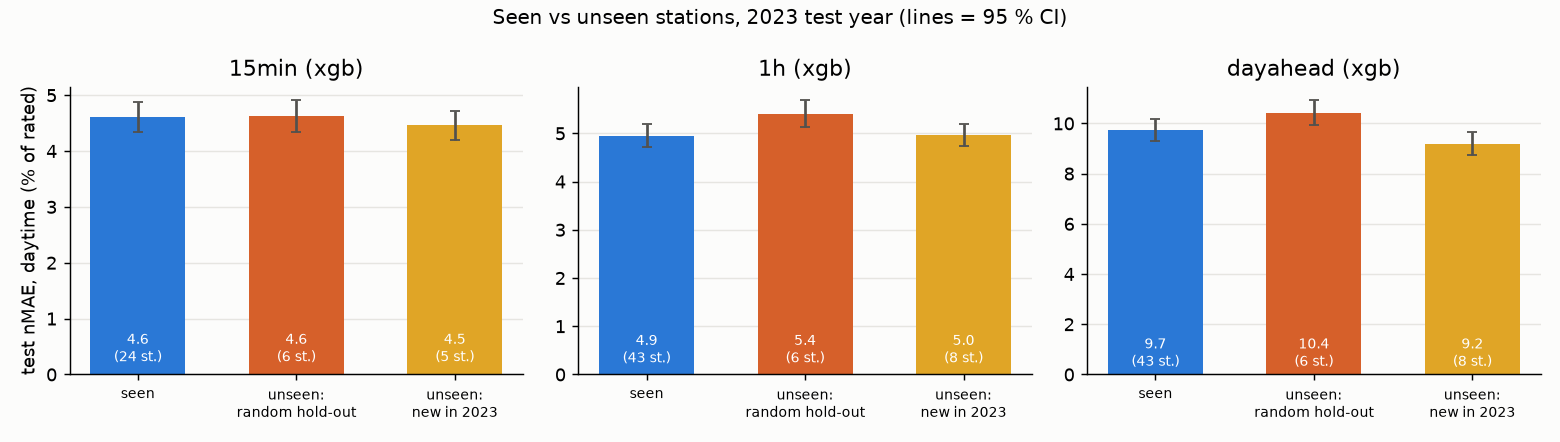

In [3]:
Image(FIGURES + "09_seen_vs_unseen.png")

The stations that are new in 2023 cover only part of the year, so their numbers are not for the same period as the seen stations. The random hold-outs are.

## 2. Station-grouped 5-fold

In [4]:
kfold = pd.read_csv(TABLES + "09_kfold.csv")
kfold.drop(columns="commit").round(3)

,horizon,model,fold,stations,nmae_left_out,nmae_trained_on,skill_left_out,skill_trained_on,nmae_gap_pct_points,nmae_gap_relative_pct
0,15min,xgb,0,5,4.863,4.867,0.117,0.116,-0.004,-0.085
1,15min,xgb,1,5,4.892,4.875,0.112,0.113,0.017,0.353
2,15min,xgb,2,5,4.292,4.173,0.094,0.104,0.118,2.839
3,15min,xgb,3,5,4.260,4.220,0.104,0.107,0.040,0.952
4,15min,xgb,4,4,4.999,4.977,0.119,0.120,0.022,0.441
5,1h,xgb,0,9,5.532,5.481,0.332,0.335,0.051,0.925
6,1h,xgb,1,9,4.612,4.544,0.363,0.371,0.068,1.487
7,1h,xgb,2,9,4.973,4.922,0.340,0.344,0.051,1.046
8,1h,xgb,3,8,5.432,5.340,0.336,0.342,0.091,1.713
9,1h,xgb,4,8,4.447,4.391,0.339,0.341,0.056,1.279


In [5]:
kfold.groupby("horizon")[["nmae_gap_pct_points", "nmae_gap_relative_pct"]].agg(["mean", "std", "min", "max"]).round(3)

nmae_gap_pct_points                      nmae_gap_relative_pct                     
                        mean    std    min    max                  mean    std    min    max
horizon                                                                                     
15min                  0.039  0.047 -0.004  0.118                 0.900  1.145 -0.085  2.839
1h                     0.063  0.017  0.051  0.091                 1.290  0.321  0.925  1.713
dayahead               0.010  0.081 -0.063  0.147                 0.119  0.885 -0.711  1.609

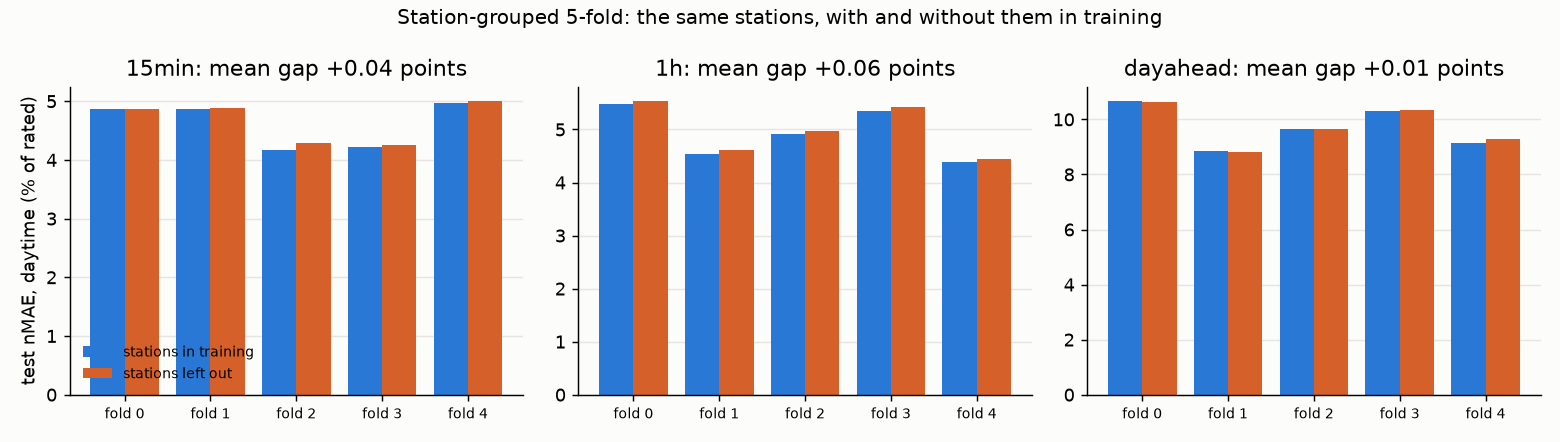

In [6]:
Image(FIGURES + "09_kfold.png")

## 3. Kaggle transfer sanity check
Limits: the Kaggle data is from 2024-2025 (no overlap), panel-optimizer level, with its own weather
station; its capacity is not in the files, so a proxy is used; its timestamp convention is not stated.
Time, hardware and weather source change together, so this is **not** an out-of-time benchmark.

In [7]:
kaggle = pd.read_csv(TABLES + "09_kaggle_transfer.csv")
kaggle[["data", "model", "n_rows", "n_days", "nmae_pct", "skill", "skill_low", "skill_high", "capacity_proxy_kW"]].round(3)

,data,model,n_rows,n_days,nmae_pct,skill,skill_low,skill_high,capacity_proxy_kW
0,HKUST test 2023 (seen stations),reduced lgbm,168250,365,4.956,0.345,0.320,0.369,NaN
1,HKUST test 2023 (seen stations),smart_persistence,168250,365,5.672,0.277,0.257,0.297,NaN
2,Kaggle rooftop 2024-2025 (zero-shot),reduced lgbm,5561,509,6.094,0.327,0.309,0.347,26.412
3,Kaggle rooftop 2024-2025 (zero-shot),smart_persistence,5561,509,6.313,0.300,0.283,0.318,26.412


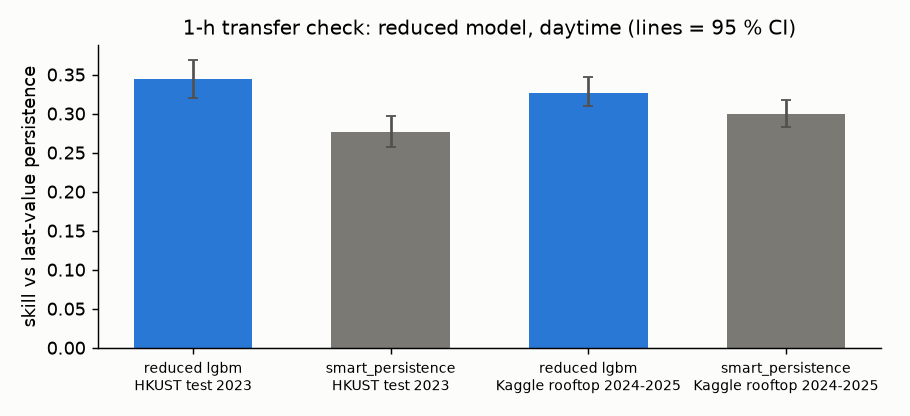

In [8]:
Image(FIGURES + "09_kaggle_transfer.png")